# 03 · Clustering: ¿qué tipos de trayectoria existen?

Aprendizaje **no supervisado** sobre las personas con al menos un año de presencia entre 2022 y 2025.
Cada persona se resume en un vector de rasgos de su trayectoria (cuántos años aparece, cuántos meses por año,
cuántas entidades, huecos, honorario, etc.). Probamos **K-means** con k = 2…8 (codo + silueta) y lo comparamos
con un **modelo de mezclas gaussianas (GMM)**.

**Censura a la derecha y a la izquierda.** Una persona que aparece por primera vez en 2025 solo tiene un año
observable. Por eso las tasas se calculan sobre los **años observables** (desde su primer año en la ventana
hasta 2025) y no sobre 4 años fijos. Aun así, los recién llegados se parecen a los "ocasionales" porque todavía
no sabemos si van a continuar; lo reportamos en el perfil.

In [1]:
# --- Configuración común: rutas (Colab o local), constantes de ley y estilo de gráficas ---
import os, sys, json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, PercentFormatter
from cycler import cycler
warnings.filterwarnings('ignore')

EN_COLAB = 'google.colab' in sys.modules
if EN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    RAIZ_DRIVE = Path('/content/drive/MyDrive/Proyecto Final SECOP')
    DATA_DIR = RAIZ_DRIVE / 'data' / 'processed'
    assert DATA_DIR.exists(), (f'No encuentro {DATA_DIR}. Sube la carpeta "Proyecto Final SECOP" (con data/processed/'
                               'secop_ps_AAAA.parquet, ver README.md) a la raíz de "Mi unidad" y vuelve a ejecutar.')
    # Las salidas quedan en "Proyecto Final SECOP/proyecto_secop/" para que las rutas relativas funcionen
    CARPETA_NB = RAIZ_DRIVE / 'proyecto_secop' / 'notebooks'
    CARPETA_NB.mkdir(parents=True, exist_ok=True)
    os.chdir(CARPETA_NB)
else:
    # Local: variable de entorno SECOP_DATA o, si no existe, la estructura del README relativa al notebook
    # (proyecto_secop/ junto a data/, o proyecto_secop/ dentro de la carpeta del proyecto).
    candidatos = [os.environ.get('SECOP_DATA'), '../data/processed', '../../data/processed']
    DATA_DIR = next((Path(c) for c in candidatos if c and Path(c).exists()), None)
    assert DATA_DIR is not None, ('No encuentro los parquet. Define la variable de entorno SECOP_DATA con la ruta a '
                                  'data/processed (ver README.md) o ubica proyecto_secop/ junto a la carpeta data/.')

# Salidas con rutas relativas a la carpeta notebooks/
OUT = Path('../outputs'); FIGS = OUT / 'figs'; TABLAS = OUT / 'tablas'; INTER = Path('../data_intermedia')
for _p in (FIGS, TABLAS, INTER):
    _p.mkdir(parents=True, exist_ok=True)
RESULTADOS = OUT / 'resultados.json'

# Constantes de ley (no son datos externos: salario mínimo decretado y regla del IBC del independiente)
SMMLV = {2020: 877_803, 2021: 908_526, 2022: 1_000_000, 2023: 1_160_000,
         2024: 1_300_000, 2025: 1_423_500, 2026: 1_750_905}   # 2026: Decreto 1469 de 2025 (verificado)
FRACCION_IBC = 0.40          # el IBC del independiente es el 40% del honorario mensual
SEMANAS_PENSION = 1300       # semanas exigidas para pensión de vejez (Colpensiones)
DIAS_MES = 30.4375           # 365,25 / 12, para pasar duración en días a meses
SEMILLA = 42

# --- Estilo de gráficas para diapositivas: sobrio, letra grande, sin adornos ---
COLOR = {'azul': '#2a78d6', 'naranja': '#eb6834', 'aqua': '#1baf7a', 'amarillo': '#eda100',
         'magenta': '#e87ba4', 'verde': '#008300', 'violeta': '#6250d6', 'rojo': '#e34948',
         'gris': '#9b9a95', 'gris_claro': '#d9d8d3', 'tinta': '#0b0b0b', 'tinta2': '#52514e'}
SERIE = [COLOR[c] for c in ('azul', 'naranja', 'aqua', 'amarillo', 'magenta', 'verde', 'violeta', 'rojo')]
mpl.rcParams.update({
    'figure.figsize': (11, 6), 'figure.dpi': 100, 'savefig.dpi': 200, 'savefig.bbox': 'tight',
    'figure.facecolor': 'white', 'axes.facecolor': 'white', 'font.family': 'DejaVu Sans',
    'font.size': 15, 'axes.titlesize': 20, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'axes.titlepad': 34, 'axes.labelsize': 15, 'xtick.labelsize': 13, 'ytick.labelsize': 13,
    'legend.fontsize': 13, 'legend.frameon': False, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#9b9a95', 'axes.labelcolor': COLOR['tinta2'], 'xtick.color': COLOR['tinta2'],
    'ytick.color': COLOR['tinta2'], 'text.color': COLOR['tinta'], 'axes.grid': True, 'axes.grid.axis': 'y',
    'grid.color': '#ebeae6', 'grid.linewidth': 0.9, 'axes.axisbelow': True, 'lines.linewidth': 2.5,
    'axes.prop_cycle': cycler(color=SERIE)})

def titulo(ax, texto, sub=None):
    """Título que cuenta el hallazgo + subtítulo gris con el detalle."""
    ax.set_title(texto, loc='left')
    if sub:
        ax.text(0, 1.035, sub, transform=ax.transAxes, fontsize=13, color=COLOR['tinta2'], va='bottom')

def fuente(fig, texto='Fuente: SECOP II (datos.gov.co), contratos de prestación de servicios a personas naturales.'):
    fig.text(0.01, -0.02, texto, fontsize=10.5, color=COLOR['gris'], ha='left', va='top')

def guardar(fig, nombre):
    ruta = FIGS / f'{nombre}.png'
    fig.savefig(ruta)
    print('Figura guardada:', ruta)

def num(x, d=0):
    """Formato numérico en español: 1.234.567,8"""
    s = f'{x:,.{d}f}'
    return s.replace(',', '§').replace('.', ',').replace('§', '.')

def pesos_millones(x, pos=None):
    return f'${num(x/1e6, 1)}M'

def pct(x, d=1):
    return f'{num(100*x, d)}%'

def guardar_resultados(seccion, datos):
    """Agrega/actualiza una sección en outputs/resultados.json."""
    todo = json.loads(RESULTADOS.read_text()) if RESULTADOS.exists() else {}
    todo[seccion] = datos
    RESULTADOS.write_text(json.dumps(todo, ensure_ascii=False, indent=2, default=float))
    print(f'resultados.json -> sección "{seccion}" actualizada')

print('Colab:', EN_COLAB, '| DATA_DIR:', DATA_DIR, '| existe:', DATA_DIR.exists())

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, adjusted_rand_score
import time

Colab: False | DATA_DIR: ../data/processed | existe: True


## 1. Variables de trayectoria por persona

In [2]:
pa = pd.read_parquet(INTER / 'persona_anio_2022_2025.parquet')
cob = pd.read_parquet(INTER / 'cobertura_2020_2025.parquet')
g = pa.groupby('id_persona')
P = g.agg(primer_anio=('anio', 'min'), ultimo_anio=('anio', 'max'), anios_activos=('anio', 'size'),
          meses_sum=('meses_cubiertos', 'sum'), dias_sum=('dias_cubiertos', 'sum'),
          meses_prom_activo=('meses_cubiertos', 'mean'),
          n9=('meses_cubiertos', lambda x: (x >= 9).sum()),
          honorario_mediano=('honorario_mensual_mediano', 'median'),
          n_entidades_prom=('n_entidades', 'mean'), n_contratos_prom=('n_contratos', 'mean'),
          huecos_prom=('n_huecos', 'mean'), share_nacional=('share_entidad_nacional', 'mean'),
          cubierto_cierre_prom=('cubierto_al_cierre', 'mean'), cotiza_minimo_prom=('cotiza_minimo', 'mean'))
P['anios_obs'] = 2025 - P.primer_anio + 1
P['frac_anios_activos'] = P.anios_activos / P.anios_obs
P['meses_por_anio_obs'] = P.meses_sum / P.anios_obs
P['frac_anios_9mas'] = P.n9 / P.anios_obs
P['semanas_por_anio_obs'] = P.dias_sum / 7 / P.anios_obs
P['log_honorario'] = np.log(P.honorario_mediano.clip(3e5, 5e7))
P['anios_previos_2020_2021'] = cob[cob.anio < 2022].groupby('id_persona').size().reindex(P.index).fillna(0)
# género de la persona: el más frecuente entre los años con género definido
gen = pa[pa.genero != 'No Definido'].groupby(['id_persona', 'genero'], observed=True).size().reset_index(name='n')
gen = gen.sort_values(['id_persona', 'n'], ascending=[True, False]).drop_duplicates('id_persona').set_index('id_persona').genero
P['genero'] = gen.reindex(P.index).astype(str).replace('nan', 'No Definido')
P['departamento'] = pa.sort_values('anio').groupby('id_persona').departamento_modal.last().astype(str)
print(f'{len(P):,} personas con presencia en 2022–2025')

FEATS = ['anios_activos', 'frac_anios_activos', 'meses_por_anio_obs', 'meses_prom_activo', 'frac_anios_9mas',
         'log_honorario', 'n_entidades_prom', 'n_contratos_prom', 'huecos_prom', 'share_nacional',
         'cubierto_cierre_prom', 'anios_previos_2020_2021']
DESCRIP = {'anios_activos': 'Años con contrato en 2022–2025 (1–4)',
           'frac_anios_activos': 'Fracción de años observables con contrato',
           'meses_por_anio_obs': 'Meses con contrato por año observable',
           'meses_prom_activo': 'Meses con contrato en los años activos',
           'frac_anios_9mas': 'Fracción de años observables con 9+ meses',
           'log_honorario': 'Log del honorario mensual mediano',
           'n_entidades_prom': 'Entidades distintas por año activo',
           'n_contratos_prom': 'Contratos por año activo',
           'huecos_prom': 'Huecos sin contrato por año activo',
           'share_nacional': 'Proporción de contratos con entidades nacionales',
           'cubierto_cierre_prom': 'Proporción de años con contrato vigente al 31-dic',
           'anios_previos_2020_2021': 'Años con contrato en 2020–2021 (0–2)'}
P[FEATS].describe().T.round(2)

848,267 personas con presencia en 2022–2025


,count,mean,std,min,25%,50%,75%,max
anios_activos,848267.0,2.15,1.13,1.00,1.00,2.00,3.00,4.00
frac_anios_activos,848267.0,0.77,0.28,0.25,0.50,1.00,1.00,1.00
meses_por_anio_obs,848267.0,5.70,3.32,0.01,2.75,5.49,8.61,12.00
meses_prom_activo,848267.0,7.20,2.96,0.03,5.03,7.63,9.73,12.00
frac_anios_9mas,848267.0,0.34,0.37,0.00,0.00,0.25,0.50,1.00
log_honorario,848267.0,15.11,0.52,12.61,14.73,15.09,15.42,17.73
n_entidades_prom,848267.0,1.08,0.27,1.00,1.00,1.00,1.00,26.50
n_contratos_prom,848267.0,1.53,0.69,1.00,1.00,1.33,2.00,36.00
huecos_prom,848267.0,0.36,0.50,0.00,0.00,0.00,0.50,8.00
share_nacional,848267.0,0.33,0.45,0.00,0.00,0.00,1.00,1.00


## 2. Estandarización
Algunas variables de conteo tienen colas largas (hasta 36 contratos al año), así que las recortamos en el
percentil 99,5 antes de estandarizar para que unos pocos casos extremos no muevan los centroides.

In [3]:
Xdf = P[FEATS].copy()
for c in ['n_entidades_prom', 'n_contratos_prom', 'huecos_prom']:
    Xdf[c] = Xdf[c].clip(upper=Xdf[c].quantile(0.995))
scaler = StandardScaler()
X = scaler.fit_transform(Xdf)
rng = np.random.default_rng(SEMILLA)
idx_sil = rng.choice(len(X), 20_000, replace=False)       # muestra para la silueta (es O(n²))
idx_gmm = rng.choice(len(X), 100_000, replace=False)      # muestra para el GMM

## 3. K-means con k = 2…8: codo y silueta

In [4]:
K = 4
# Silueta en 3 muestras distintas de 20.000 personas (media ± desviación) para ver si las diferencias son reales
idx_sils = [np.random.default_rng(s).choice(len(X), 20_000, replace=False) for s in (1, 2, 3)]
res_k, modelos = [], {}
for k in range(2, 9):
    t0 = time.time()
    # n_init alto: con pocas inicializaciones K-means cae en óptimos locales distintos (sobre todo con k = 4)
    km = KMeans(n_clusters=k, n_init=20 if k == K else 10, random_state=SEMILLA).fit(X)
    sils = [silhouette_score(X[i], km.labels_[i]) for i in idx_sils]
    res_k.append({'k': k, 'inercia': km.inertia_, 'silueta': float(np.mean(sils)), 'silueta_sd': float(np.std(sils))})
    modelos[k] = km
    print(f'k={k}  inercia={km.inertia_:,.0f}  silueta={np.mean(sils):.3f} ± {np.std(sils):.3f}  ({time.time()-t0:.0f}s)')
res_k = pd.DataFrame(res_k)
res_k.to_csv(TABLAS / '03_kmeans_codo_silueta.csv', index=False)

k=2  inercia=7,634,007  silueta=0.231 ± 0.000  (17s)


k=3  inercia=6,906,573  silueta=0.186 ± 0.002  (20s)


k=4  inercia=6,267,857  silueta=0.193 ± 0.002  (27s)


k=5  inercia=5,808,042  silueta=0.155 ± 0.002  (21s)


k=6  inercia=5,434,654  silueta=0.153 ± 0.002  (24s)


k=7  inercia=5,174,521  silueta=0.154 ± 0.003  (25s)


k=8  inercia=4,900,780  silueta=0.154 ± 0.002  (27s)


### Estabilidad de la solución con k = 4
Volvemos a ajustar K-means con otras dos semillas (n_init = 20) y sobre una submuestra del 50%, y medimos la
concordancia con la solución elegida usando el índice de Rand ajustado (ARI: 1 = misma partición).

In [5]:
estab = []
for sem in (123, 2024):
    km_s = KMeans(n_clusters=K, n_init=20, random_state=sem).fit(X)
    estab.append({'prueba': f'semilla {sem} (n_init=20)', 'inercia': km_s.inertia_,
                  'ARI_vs_solucion': adjusted_rand_score(modelos[K].labels_, km_s.labels_)})
idx_sub = np.random.default_rng(7).choice(len(X), len(X) // 2, replace=False)
km_sub = KMeans(n_clusters=K, n_init=10, random_state=SEMILLA).fit(X[idx_sub])
estab.append({'prueba': 'submuestra 50% (n_init=10)', 'inercia': np.nan,
              'ARI_vs_solucion': adjusted_rand_score(modelos[K].labels_[idx_sub], km_sub.labels_)})
km_1 = KMeans(n_clusters=K, n_init=1, random_state=2024).fit(X)
estab.append({'prueba': 'semilla 2024 con n_init=1 (referencia)', 'inercia': km_1.inertia_,
              'ARI_vs_solucion': adjusted_rand_score(modelos[K].labels_, km_1.labels_)})
estab = pd.DataFrame(estab)
estab.loc[len(estab)] = {'prueba': 'solución elegida (semilla 42, n_init=20)', 'inercia': modelos[K].inertia_, 'ARI_vs_solucion': 1.0}
estab.to_csv(TABLAS / '03_estabilidad_kmeans_k4.csv', index=False)
del km_s, km_sub, km_1
estab.round(4)

,prueba,inercia,ARI_vs_solucion
0,semilla 123 (n_init=20),6.267858e+06,0.9994
1,semilla 2024 (n_init=20),6.267853e+06,0.9987
2,submuestra 50% (n_init=10),NaN,0.9972
3,semilla 2024 con n_init=1 (referencia),6.398158e+06,0.4408
4,"solución elegida (semilla 42, n_init=20)",6.267857e+06,1.0000


**Lectura.** Con k = 4 la función objetivo de K-means tiene varios óptimos locales. La revisión independiente
encontró que, con `n_init=4`, algunas semillas caen en una partición distinta, con una inercia un 2% peor
(ARI ≈ 0,44–0,67). Con `n_init=20` las distintas semillas llegan a la misma solución (ARI cercano a 1), y la
partición también se mantiene en una submuestra del 50%. Por eso usamos `n_init=20` para la solución final.

Figura guardada: ../outputs/figs/03_kmeans_codo_silueta.png


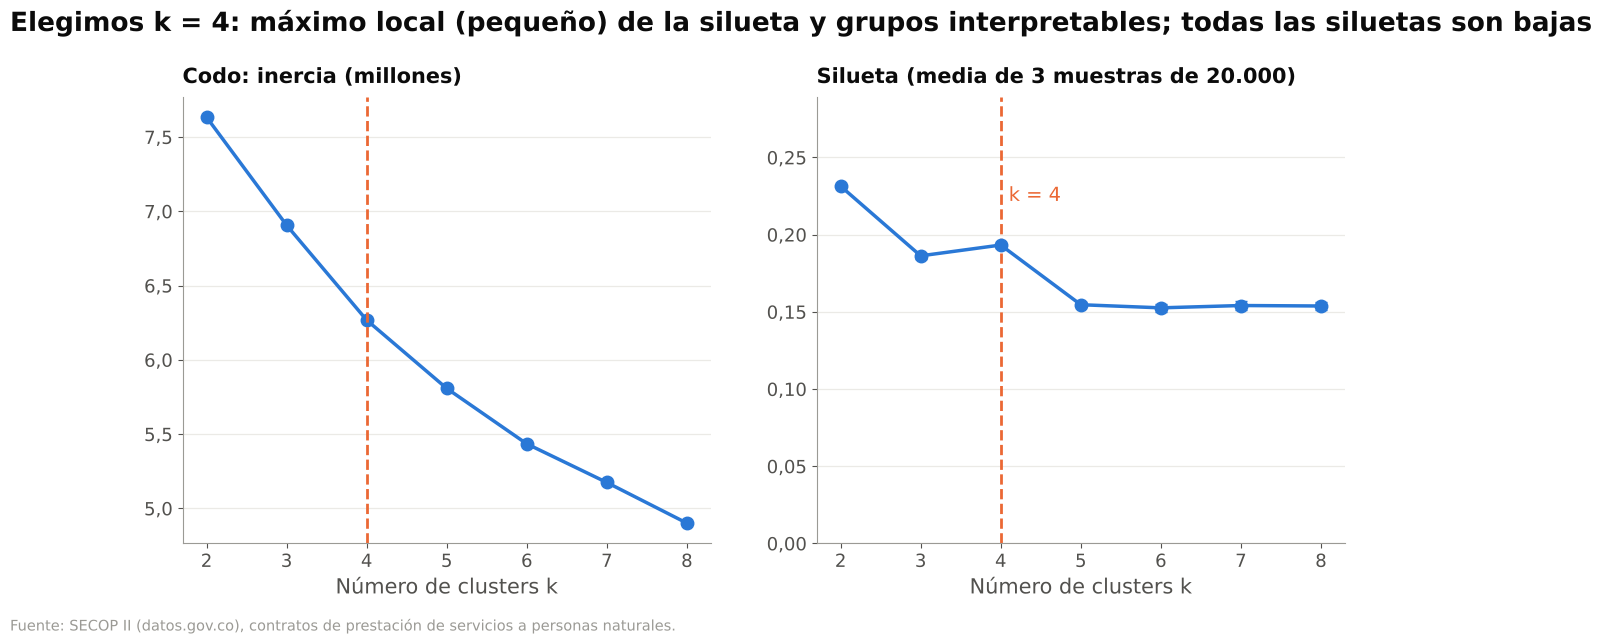

In [6]:
fig, axs = plt.subplots(1, 2, figsize=(15, 5.8))
axs[0].plot(res_k.k, res_k.inercia / 1e6, marker='o', color=COLOR['azul'], ms=9)
axs[0].set_title('Codo: inercia (millones)', fontsize=15, pad=10); axs[0].set_xlabel('Número de clusters k')
axs[1].errorbar(res_k.k, res_k.silueta, yerr=res_k.silueta_sd, marker='o', color=COLOR['azul'], ms=9, capsize=4)
axs[1].set_ylim(0, res_k.silueta.max() * 1.25)
axs[1].yaxis.set_major_formatter(FuncFormatter(lambda v, p: num(v, 2)))
axs[0].yaxis.set_major_formatter(FuncFormatter(lambda v, p: num(v, 1)))
axs[1].set_title('Silueta (media de 3 muestras de 20.000)', fontsize=15, pad=10); axs[1].set_xlabel('Número de clusters k')
for ax in axs:
    ax.axvline(K, color=COLOR['naranja'], ls='--', lw=2)
axs[1].text(K + 0.1, res_k.silueta.max(), f'k = {K}', color=COLOR['naranja'], fontsize=14, va='top')
fig.suptitle('Elegimos k = 4: máximo local (pequeño) de la silueta y grupos interpretables; todas las siluetas son bajas',
             x=0.01, ha='left', fontsize=19, fontweight='bold', y=1.03)
fuente(fig); guardar(fig, '03_kmeans_codo_silueta'); plt.show()

**¿Por qué k = 4?** La silueta más alta está en k = 2, pero ese corte solo separa "los que siguen" de "los que no".
Después la silueta cae y tiene un **máximo local en k = 4**, pequeño pero mayor que la variación entre muestras
(ver las barras de error). Luego vuelve a bajar desde k = 5. La curva del codo no
muestra un quiebre fuerte, algo típico en datos continuos como estos. Con k = 4 aparecen grupos distintos y
útiles para la política pública. Las siluetas son bajas (≈ 0,18–0,23): las trayectorias forman un **continuo**
y no grupos bien separados, así que leemos los clusters como "tipos" y no como categorías naturales.

## 4. Comparación con un GMM (mezcla gaussiana)

In [7]:
Xg = X[idx_gmm]
bic = []
for k in range(2, 9):
    gm = GaussianMixture(n_components=k, covariance_type='full', random_state=SEMILLA, n_init=2).fit(Xg)
    bic.append({'k': k, 'bic': gm.bic(Xg)})
bic = pd.DataFrame(bic)
gmm = GaussianMixture(n_components=K, covariance_type='full', random_state=SEMILLA, n_init=3).fit(Xg)
lab_gmm = gmm.predict(Xg)
lab_km = modelos[K].labels_[idx_gmm]
ari = adjusted_rand_score(lab_km, lab_gmm)
sil_gmm = silhouette_score(X[idx_sil], gmm.predict(X[idx_sil]))
print(bic)
print(f'ARI K-means vs GMM (k={K}): {ari:.3f} · silueta GMM: {sil_gmm:.3f} vs K-means: {res_k.set_index("k").silueta[K]:.3f}')
bic.to_csv(TABLAS / '03_gmm_bic.csv', index=False)
pd.crosstab(pd.Series(lab_km, name='K-means'), pd.Series(lab_gmm, name='GMM'), normalize='index').round(2)

   k           bic
0  2  6.378742e+05
1  3 -5.491026e+04
2  4 -7.335831e+05
3  5 -1.137890e+06
4  6 -1.468615e+06
5  7 -1.988912e+06
6  8 -1.932396e+06
ARI K-means vs GMM (k=4): 0.125 · silueta GMM: 0.089 vs K-means: 0.193


GMM,0,1,2,3
K-means,,,,
0,0.06,0.31,0.02,0.61
1,0.28,0.00,0.72,0.00
2,0.09,0.07,0.12,0.72
3,0.05,0.35,0.30,0.31


**Lectura de la comparación.**
- El BIC del GMM baja casi sin parar hasta k = 7. Con 100 mil personas y covarianzas completas, casi siempre
  "paga" agregar componentes, así que el BIC no da un k interpretable.
- Con k = 4, la concordancia entre GMM y K-means es **baja** (ARI ≈ 0,13) y la silueta del GMM es menor (≈ 0,09
  frente a ≈ 0,19). El GMM separa por la **forma** de la distribución: por ejemplo, aísla a quienes tienen
  exactamente 1 contrato y 0 huecos, que son valores "pegados" en un punto. No separa por el nivel de
  continuidad.
- Por eso nos quedamos con **K-means** para describir trayectorias. La tabla cruzada muestra que los dos métodos
  parten los datos de forma distinta: algunos grupos de K-means se concentran en uno o dos componentes del GMM,
  pero otros se reparten entre tres. La conclusión es que la segmentación **depende del método** y que los datos
  no tienen fronteras naturales. Los clusters son una forma útil de resumir un continuo, no grupos "reales".

## 5. Perfil de cada cluster y nombres

In [8]:
P['cluster'] = modelos[K].labels_
perfil = P.groupby('cluster').agg(
    personas=('anios_activos', 'size'), anios_activos=('anios_activos', 'mean'),
    meses_por_anio_obs=('meses_por_anio_obs', 'mean'), meses_prom_activo=('meses_prom_activo', 'mean'),
    frac_anios_9mas=('frac_anios_9mas', 'mean'), honorario_mediano=('honorario_mediano', 'median'),
    n_entidades_prom=('n_entidades_prom', 'mean'), n_contratos_prom=('n_contratos_prom', 'mean'),
    huecos_prom=('huecos_prom', 'mean'), share_nacional=('share_nacional', 'mean'),
    cubierto_cierre=('cubierto_cierre_prom', 'mean'), anios_previos=('anios_previos_2020_2021', 'mean'),
    semanas_por_anio_mediana=('semanas_por_anio_obs', 'median'), cotiza_minimo=('cotiza_minimo_prom', 'mean'),
    pct_mujer=('genero', lambda s: (s == 'Mujer').mean() / max((s != 'No Definido').mean(), 1e-9)),
    pct_entra_2025=('primer_anio', lambda s: (s == 2025).mean()),
    pct_activo_2025=('ultimo_anio', lambda s: (s == 2025).mean()))
perfil['pct_personas'] = perfil.personas / perfil.personas.sum()

# Nombres por reglas sobre el perfil (reproducible si cambian las etiquetas numéricas)
nombres = {}
c_multi = perfil.n_entidades_prom.idxmax(); nombres[c_multi] = 'Multientidad'
# Verificamos el perfil en vez de nombrar a ciegas (un óptimo local distinto produce otro "Multientidad")
assert perfil.loc[c_multi, 'n_entidades_prom'] > 1.6, 'El cluster con más entidades no tiene un perfil multientidad'
resto = perfil.drop(c_multi)
nombres[resto.meses_por_anio_obs.idxmax()] = 'Estables'
nombres[resto.meses_por_anio_obs.idxmin()] = 'Ocasionales'
for c in perfil.index:
    nombres.setdefault(c, 'Intermitentes')
ORDEN = ['Estables', 'Multientidad', 'Intermitentes', 'Ocasionales']
COL_CLUSTER = {'Estables': COLOR['azul'], 'Multientidad': COLOR['aqua'], 'Intermitentes': COLOR['violeta'],
               'Ocasionales': COLOR['naranja']}
perfil['nombre'] = perfil.index.map(nombres)
perfil = perfil.set_index('nombre').loc[ORDEN]
P['nombre_cluster'] = P.cluster.map(nombres)
perfil.to_csv(TABLAS / '03_perfil_clusters.csv')
perfil.T.round(3)

nombre,Estables,Multientidad,Intermitentes,Ocasionales
personas,249680.000,55872.000,184455.000,358260.000
anios_activos,3.117,2.884,2.094,1.396
meses_por_anio_obs,9.018,8.072,5.936,2.894
meses_prom_activo,9.511,9.186,7.864,4.937
frac_anios_9mas,0.725,0.585,0.286,0.058
honorario_mediano,4129729.391,4964480.231,2980814.089,3281942.717
n_entidades_prom,1.044,1.897,1.030,1.009
n_contratos_prom,1.465,2.737,2.107,1.079
huecos_prom,0.318,0.449,1.004,0.049
share_nacional,0.498,0.316,0.099,0.343


### Cómo leer los cuatro tipos de trayectoria
- **Estables**: aparecen casi todos los años, con unos 9 meses o más por año, en general 1 contrato largo con una
  sola entidad y más presencia en entidades nacionales. Son el "núcleo" que se renueva año a año.
- **Multientidad**: en promedio casi 2 entidades distintas por año (1,9), y cerca de la mitad trabaja con 2 o más.
  Firman varios contratos al año, tienen el honorario más alto y buena cobertura. Es un grupo pequeño. Ojo:
  `n_entidades` cuenta entidades distintas en el año, no necesariamente simultáneas.
- **Intermitentes**: contratos cortos con huecos entre uno y otro (alrededor de 1 hueco por año activo). Están
  activos unos 2 de 4 años y muchos dejan de aparecer después de 2023: solo el 59% sigue activo en 2025. Son sobre
  todo territoriales y cotizan sobre el mínimo con más frecuencia.
- **Ocasionales**: aparecen 1 o 2 años, con pocos meses y casi siempre un solo contrato. Son el grupo más grande.
  **Censura:** el 23% de ellos entra en 2025 y solo tiene un año observable, así que una parte de este grupo son
  recién llegados de quienes todavía no sabemos si van a continuar.

In [9]:
tabla_pres = perfil[['personas', 'pct_personas', 'anios_activos', 'meses_por_anio_obs', 'frac_anios_9mas',
                     'n_entidades_prom', 'n_contratos_prom', 'huecos_prom', 'honorario_mediano', 'share_nacional',
                     'cotiza_minimo', 'semanas_por_anio_mediana', 'pct_mujer', 'pct_entra_2025']].copy()
tabla_pres.columns = ['Personas', '% personas', 'Años activos (de 4)', 'Meses/año observable', '% años con 9+ meses',
                      'Entidades/año', 'Contratos/año', 'Huecos/año', 'Honorario mediano', '% con entidad nacional',
                      '% años cotiza mínimo', 'Semanas/año (mediana)', '% mujeres', '% que entra en 2025']
tabla_pres.to_csv(TABLAS / '03_tabla_perfiles_presentacion.csv')
tabla_pres.style.format({'Personas': lambda v: num(v), '% personas': lambda v: pct(v), 'Años activos (de 4)': '{:.2f}',
                         'Meses/año observable': '{:.1f}', '% años con 9+ meses': lambda v: pct(v),
                         'Entidades/año': '{:.2f}', 'Contratos/año': '{:.2f}', 'Huecos/año': '{:.2f}',
                         'Honorario mediano': lambda v: pesos_millones(v), '% con entidad nacional': lambda v: pct(v),
                         '% años cotiza mínimo': lambda v: pct(v), 'Semanas/año (mediana)': '{:.1f}',
                         '% mujeres': lambda v: pct(v), '% que entra en 2025': lambda v: pct(v)})

,Personas,% personas,Años activos (de 4),Meses/año observable,% años con 9+ meses,Entidades/año,Contratos/año,Huecos/año,Honorario mediano,% con entidad nacional,% años cotiza mínimo,Semanas/año (mediana),% mujeres,% que entra en 2025
nombre,,,,,,,,,,,,,,
Estables,249.680,"29,4%",3.12,9.0,"72,5%",1.04,1.46,0.32,"$4,1M","49,8%","28,8%",40.6,"41,7%","8,2%"
Multientidad,55.872,"6,6%",2.88,8.1,"58,5%",1.90,2.74,0.45,"$5,0M","31,6%","16,8%",37.8,"36,6%","8,4%"
Intermitentes,184.455,"21,7%",2.09,5.9,"28,6%",1.03,2.11,1.00,"$3,0M","9,9%","53,3%",25.2,"48,4%","13,4%"
Ocasionales,358.260,"42,2%",1.40,2.9,"5,8%",1.01,1.08,0.05,"$3,3M","34,3%","45,7%",11.4,"49,0%","22,8%"


## 6. Visualizaciones

Figura guardada: ../outputs/figs/03_perfil_clusters.png


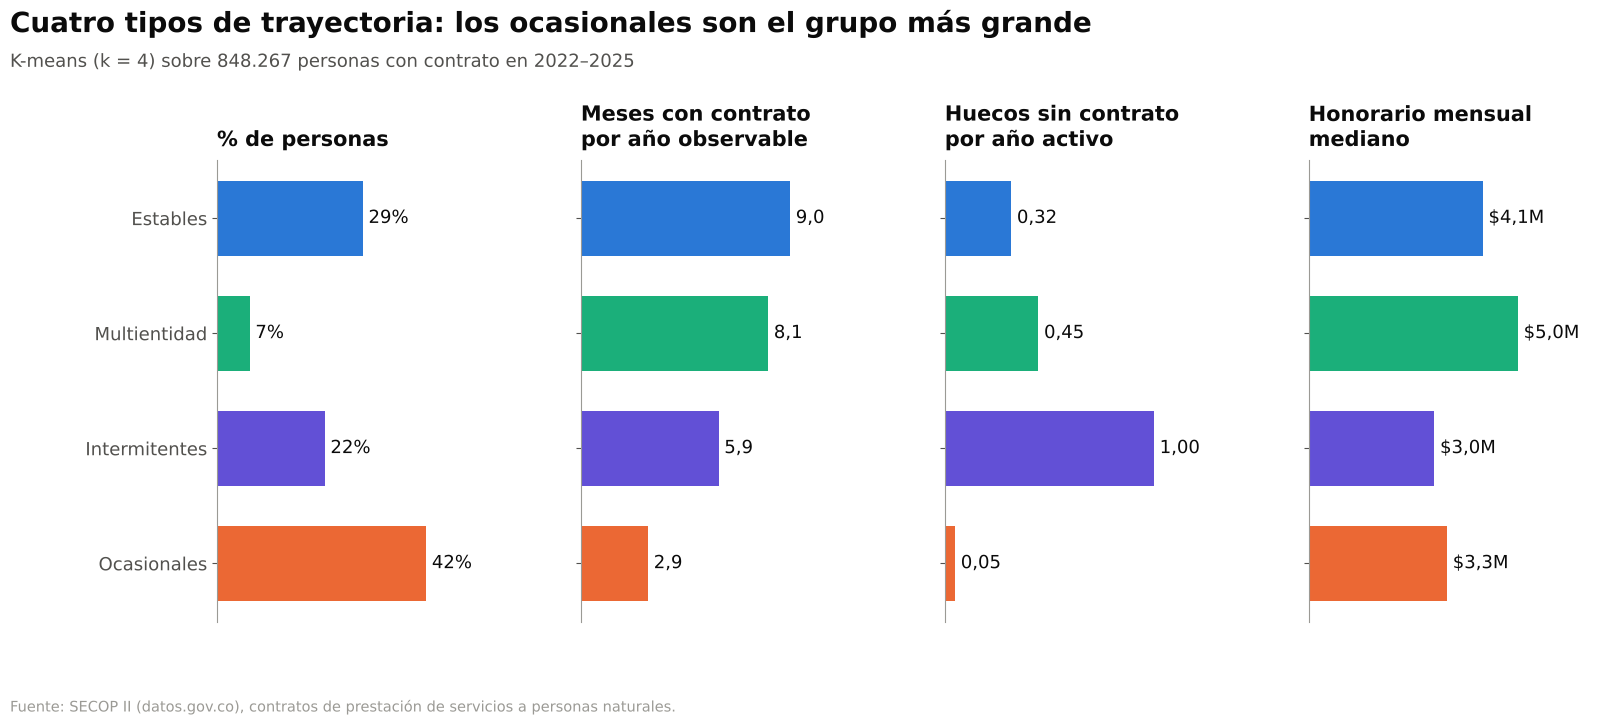

In [10]:
# Perfil en 4 paneles (una escala por panel)
fig, axs = plt.subplots(1, 4, figsize=(18, 6))
paneles = [('pct_personas', '% de personas', lambda v: pct(v, 0)),
           ('meses_por_anio_obs', 'Meses con contrato\npor año observable', lambda v: num(v, 1)),
           ('huecos_prom', 'Huecos sin contrato\npor año activo', lambda v: num(v, 2)),
           ('honorario_mediano', 'Honorario mensual\nmediano', pesos_millones)]
for ax, (col, lab, f) in zip(axs, paneles):
    vals = perfil[col]
    ax.barh(range(len(vals))[::-1], vals.values, color=[COL_CLUSTER[n] for n in vals.index], height=0.65)
    for i, v in zip(range(len(vals))[::-1], vals.values):
        ax.text(v, i, ' ' + f(v), va='center', fontsize=13)
    ax.set_yticks(range(len(vals))[::-1]); ax.set_yticklabels(vals.index if ax is axs[0] else [])
    ax.set_title(lab, fontsize=15, pad=10); ax.set_xticks([]); ax.grid(False)
    ax.spines['bottom'].set_visible(False); ax.set_xlim(0, vals.max() * 1.45)
fig.suptitle('Cuatro tipos de trayectoria: los ocasionales son el grupo más grande',
             x=0.01, ha='left', fontsize=20, fontweight='bold', y=1.13)
fig.text(0.01, 1.035, f'K-means (k = 4) sobre {num(len(P))} personas con contrato en 2022–2025', fontsize=13, color=COLOR['tinta2'])
fuente(fig); guardar(fig, '03_perfil_clusters'); plt.show()

Figura guardada: ../outputs/figs/03_trayectoria_media_por_cluster.png


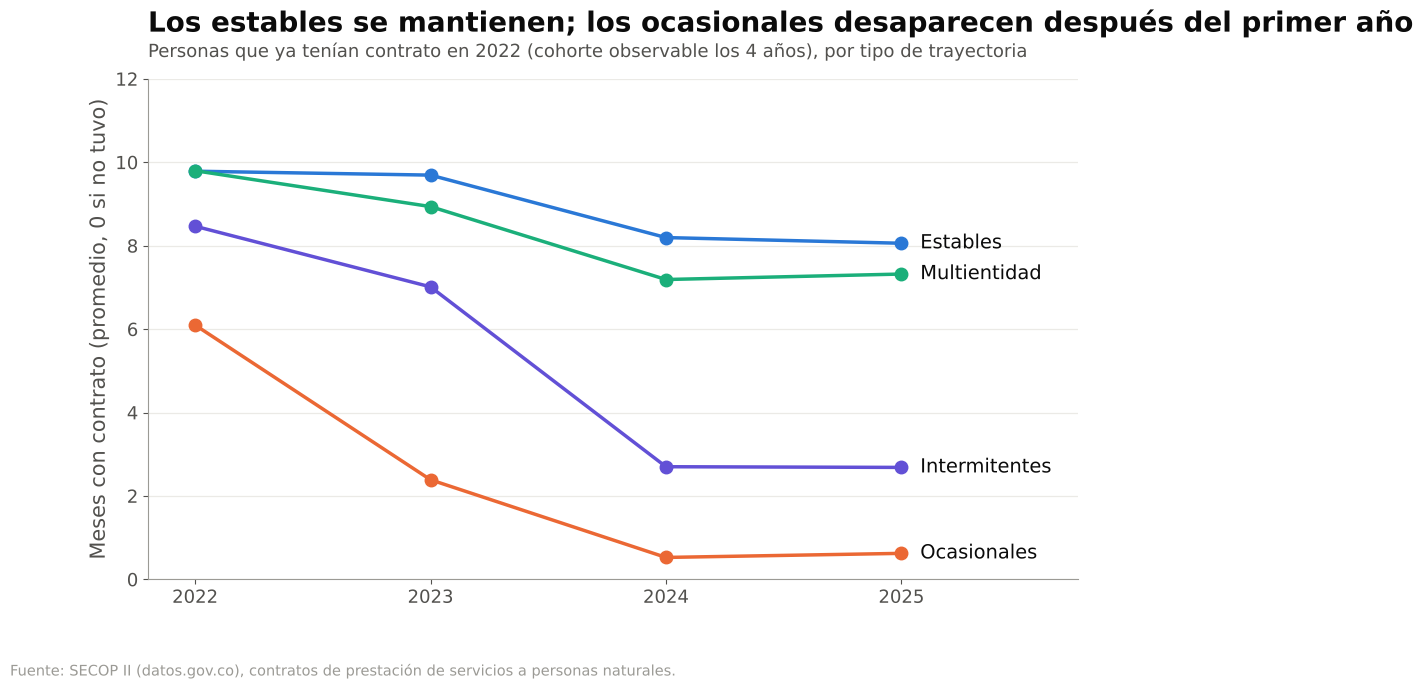

In [11]:
# Trayectoria promedio: meses cubiertos por año (0 si no tuvo contrato), solo años observables
tray = pa[['id_persona', 'anio', 'meses_cubiertos']].merge(P[['nombre_cluster', 'primer_anio']], left_on='id_persona', right_index=True)
completo = P[P.primer_anio == 2022][['nombre_cluster']].copy()       # cohorte observable los 4 años
mat = pa[pa.id_persona.isin(completo.index)].pivot_table(index='id_persona', columns='anio', values='meses_cubiertos', fill_value=0)
mat = mat.join(completo)
tr = mat.groupby('nombre_cluster')[[2022, 2023, 2024, 2025]].mean().loc[ORDEN]
tr.to_csv(TABLAS / '03_trayectoria_media_cohorte_2022.csv')
fig, ax = plt.subplots(figsize=(12, 6.5))
for n in ORDEN:
    ax.plot(tr.columns, tr.loc[n], marker='o', ms=9, color=COL_CLUSTER[n], label=n)
    ax.text(2025.08, tr.loc[n, 2025], n, va='center', fontsize=14, color=COLOR['tinta'])
ax.set_xticks([2022, 2023, 2024, 2025]); ax.set_xlim(2021.8, 2025.75); ax.set_ylim(0, 12)
ax.set_ylabel('Meses con contrato (promedio, 0 si no tuvo)')
titulo(ax, 'Los estables se mantienen; los ocasionales desaparecen después del primer año',
       'Personas que ya tenían contrato en 2022 (cohorte observable los 4 años), por tipo de trayectoria')
fuente(fig); guardar(fig, '03_trayectoria_media_por_cluster'); plt.show()

Figura guardada: ../outputs/figs/03_pca_2d_clusters.png


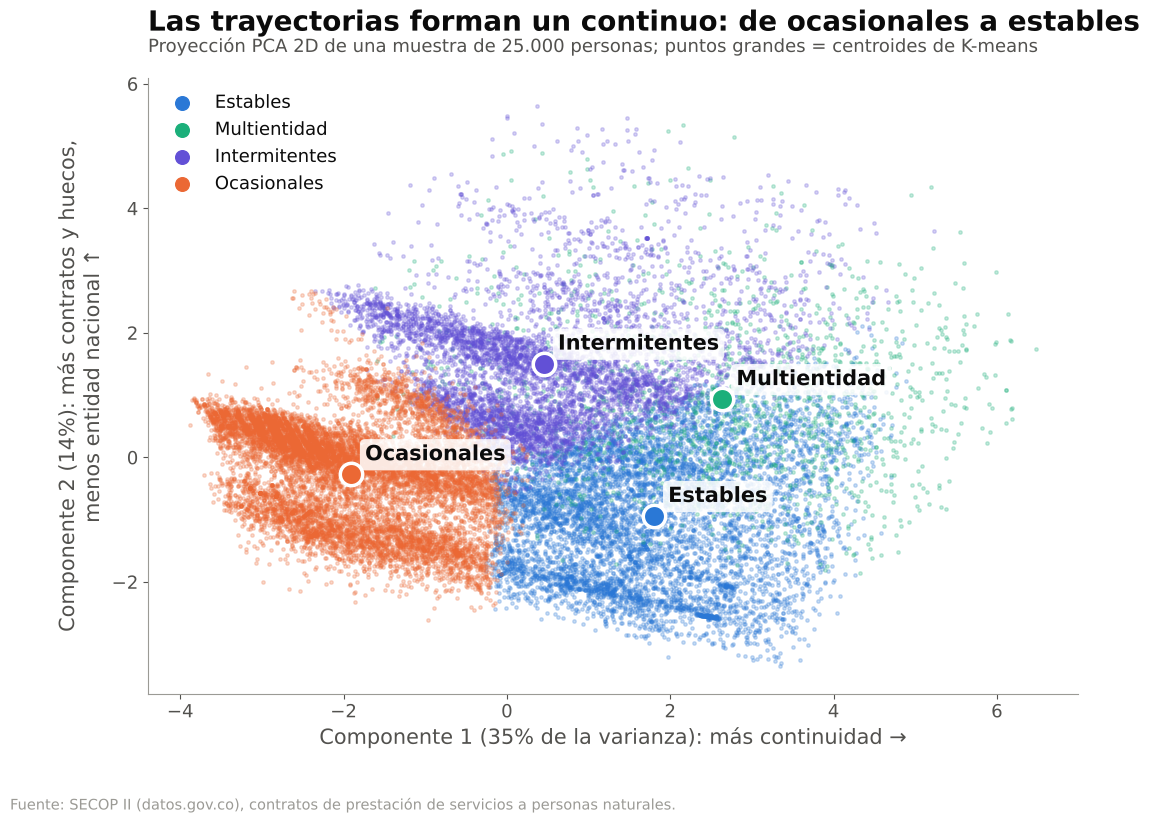

Cargas PCA:
                          PC1   PC2
anios_activos            0.37 -0.09
frac_anios_activos       0.30 -0.13
meses_por_anio_obs       0.45 -0.12
meses_prom_activo        0.38 -0.05
frac_anios_9mas          0.41 -0.17
log_honorario            0.11 -0.27
n_entidades_prom         0.18  0.15
n_contratos_prom         0.30  0.52
huecos_prom              0.22  0.55
share_nacional           0.04 -0.50
cubierto_cierre_prom     0.18 -0.10
anios_previos_2020_2021  0.21 -0.09
Mayores cargas PC1: ['meses_por_anio_obs', 'frac_anios_9mas'] | PC2: ['huecos_prom', 'n_contratos_prom']


In [12]:
# PCA 2D sobre una muestra para visualizar
pca = PCA(n_components=2, random_state=SEMILLA).fit(X)
idx_v = rng.choice(len(X), 25_000, replace=False)
Z = pca.transform(X[idx_v]); nom_v = P.nombre_cluster.values[idx_v]
cargas = pd.DataFrame(pca.components_.T, index=FEATS, columns=['PC1', 'PC2'])
cargas.to_csv(TABLAS / '03_pca_cargas.csv')
fig, ax = plt.subplots(figsize=(12, 8))
for n in ORDEN:
    m = nom_v == n
    ax.scatter(Z[m, 0], Z[m, 1], s=6, alpha=0.25, color=COL_CLUSTER[n], label=n, rasterized=True)
cen = pca.transform(modelos[K].cluster_centers_)
for c, (x, y) in enumerate(cen):
    ax.scatter(x, y, s=260, color=COL_CLUSTER[nombres[c]], edgecolor='white', linewidth=2.5, zorder=3)
    ax.annotate(nombres[c], (x, y), xytext=(10, 10), textcoords='offset points', fontsize=15, fontweight='bold',
                color=COLOR['tinta'], bbox=dict(boxstyle='round,pad=0.25', fc='white', ec='none', alpha=0.85))
ev = pca.explained_variance_ratio_
top1 = cargas.PC1.abs().sort_values(ascending=False).index[:2]; top2 = cargas.PC2.abs().sort_values(ascending=False).index[:2]
ax.set_xlabel(f'Componente 1 ({pct(ev[0],0)} de la varianza): más continuidad →')
ax.set_ylabel(f'Componente 2 ({pct(ev[1],0)}): más contratos y huecos,\nmenos entidad nacional ↑')
ax.grid(False); leg = ax.legend(markerscale=4, loc='upper left')
for lh in leg.legend_handles: lh.set_alpha(1)
titulo(ax, 'Las trayectorias forman un continuo: de ocasionales a estables',
       'Proyección PCA 2D de una muestra de 25.000 personas; puntos grandes = centroides de K-means')
fuente(fig); guardar(fig, '03_pca_2d_clusters'); plt.show()
print('Cargas PCA:'); print(cargas.round(2)); print('Mayores cargas PC1:', list(top1), '| PC2:', list(top2))

## 7. Guardar resultados

In [13]:
cols_guardar = list(dict.fromkeys(['id_persona', 'cluster', 'nombre_cluster', 'primer_anio', 'ultimo_anio', 'anios_obs',
                                    'semanas_por_anio_obs', 'dias_sum', 'honorario_mediano', 'cotiza_minimo_prom',
                                    'genero', 'departamento'] + FEATS))
P.reset_index()[cols_guardar].to_parquet(INTER / 'clusters_personas.parquet', index=False)
guardar_resultados('03_clustering', {
    'n_personas': int(len(P)), 'k_elegido': K, 'variables': DESCRIP,
    'kmeans_por_k': res_k.to_dict('records'), 'gmm_bic_por_k': bic.to_dict('records'),
    'estabilidad_k4': estab.to_dict('records'),
    'pct_multientidad_con_2mas_entidades': float((P.loc[P.nombre_cluster == 'Multientidad', 'n_entidades_prom'] >= 2).mean()),
    'ari_kmeans_vs_gmm': float(ari), 'silueta_gmm': float(sil_gmm),
    'pca_varianza_explicada': [float(v) for v in ev],
    'perfiles': {n: {k: float(v) for k, v in f.items()} for n, f in perfil.iterrows()},
    'trayectoria_media_cohorte_2022': {n: {int(a): float(v) for a, v in f.items()} for n, f in tr.iterrows()}})

resultados.json -> sección "03_clustering" actualizada
